<a href="https://colab.research.google.com/github/ust-buan-640/buan-640-notebooks/blob/main/notebooks/m10-1-comparing-groups.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comparing More Than Two Groups

> "The real purpose of the scientific method is to make sure Nature hasn't misled you into thinking you know something you don't actually know." — Robert Pirsig

In Module 9 we compared two means with a t-test. In this notebook we compare three groups, see why a t-test for every pair is a problem, and meet the F statistic.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Example: scores in three sections

Test scores (out of 10) of students in three sections of the same course: morning, afternoon, and evening, with 30 students in each.

In [ ]:
test_scores = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/test_scores_eng.csv")
scores = test_scores.melt(var_name="section", value_name="score")
order = ["morning", "afternoon", "evening"]
palette = {"morning": "skyblue", "afternoon": "lightgreen", "evening": "salmon"}
scores.groupby("section", sort=False)["score"].agg(["count", "mean", "std"]).round(2)

,count,mean,std
section,,,
morning,30,7.9200,1.2700
afternoon,30,7.5000,1.3700
evening,30,7.3500,1.4300


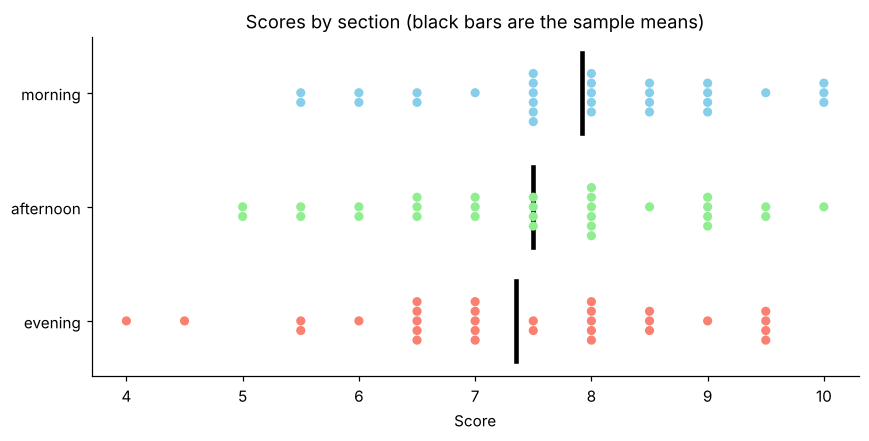

In [ ]:
plt.figure(figsize=(9, 4))
sns.swarmplot(x="score", y="section", data=scores, order=order, hue="section", palette=palette, legend=False, size=6)
for i, s in enumerate(order):
    m = scores.loc[scores["section"] == s, "score"].mean()
    plt.plot([m, m], [i - 0.35, i + 0.35], color="black", lw=3)
plt.xlabel("Score"); plt.ylabel(""); plt.title("Scores by section (black bars are the sample means)")
plt.show()

The sample means differ: 7.92, 7.50, and 7.35. Sample means always differ a little, even when the population means are equal. Are these differences larger than chance alone would produce?

## 2. Two sections: a tool we know

For morning vs. evening alone, we can use the two-sample t-test from Module 9.

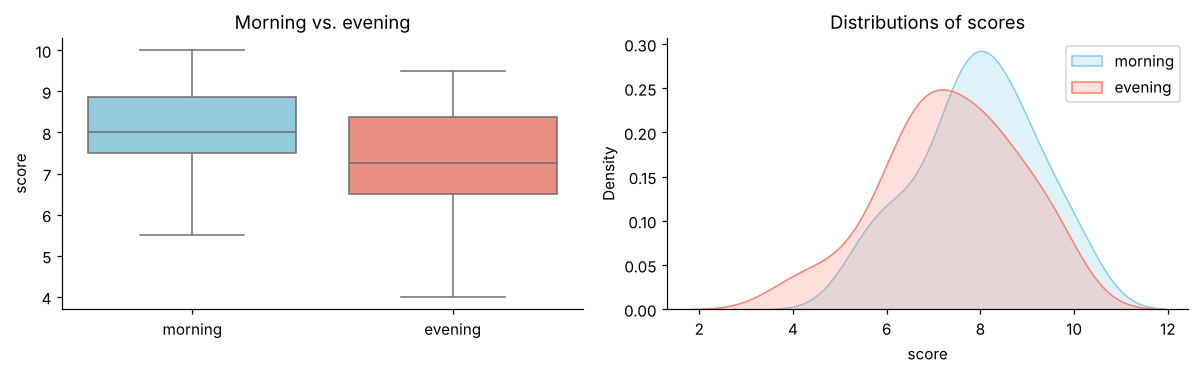

In [ ]:
me = scores[scores["section"].isin(["morning", "evening"])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(data=me, x="section", y="score", order=["morning", "evening"], hue="section", palette=palette, legend=False, ax=axes[0])
axes[0].set_title("Morning vs. evening"); axes[0].set_xlabel("")
for s in ["morning", "evening"]:
    sns.kdeplot(me.loc[me["section"] == s, "score"], fill=True, color=palette[s], label=s, ax=axes[1])
axes[1].set_title("Distributions of scores"); axes[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
morning = test_scores["morning"]
evening = test_scores["evening"]
t_stat, p_value = stats.ttest_ind(morning, evening, equal_var=False)
print(f"Difference in means: {morning.mean() - evening.mean():.2f}, t = {t_stat:.2f}, p-value = {p_value:.3f}")

Difference in means: 0.57, t = 1.62, p-value = 0.110


## 3. Why not a t-test for every pair?

With three sections there are three pairs. With six sections there would be fifteen. Each t-test at α = 0.05 has a 5% chance of a false "significant" result when there is no real difference. With several tests on the same data, the chance of **at least one** false result is larger than 5%, and it grows with the number of groups.

The simulation below creates a world where all population means are equal, draws 30 students per group, runs a t-test for every pair, and records whether at least one pair came out "significant". It repeats this 2,000 times for each number of groups.

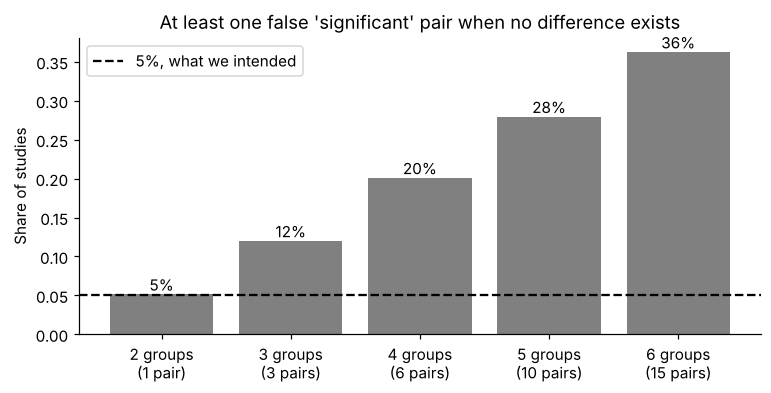

In [ ]:
rng = np.random.default_rng(1)
ks, shares = [2, 3, 4, 5, 6], []
for k in ks:
    hits = 0
    for _ in range(2000):
        g = rng.normal(7.5, 1.35, size=(k, 30))
        p_min = min(stats.ttest_ind(g[i], g[j]).pvalue for i in range(k) for j in range(i + 1, k))
        hits += p_min < 0.05
    shares.append(hits / 2000)
plt.figure(figsize=(8, 3.5))
plt.bar([f"{k} groups\n({k * (k - 1) // 2} pair{'s' if k > 2 else ''})" for k in ks], shares, color="gray")
plt.axhline(0.05, color="black", ls="--", label="5%, what we intended")
for i, s in enumerate(shares): plt.text(i, s, f"{s:.0%}", ha="center", va="bottom")
plt.ylabel("Share of studies"); plt.title("At least one false 'significant' pair when no difference exists")
plt.legend(); plt.show()

![xkcd 882](https://imgs.xkcd.com/comics/significant.png)

*[xkcd 882, "Significant"](https://xkcd.com/882/), Randall Munroe, CC BY-NC 2.5.*

The solution is to ask one question about all groups at once.

## 4. One question about all groups

H<sub>0</sub>: μ<sub>morning</sub> = μ<sub>afternoon</sub> = μ<sub>evening</sub>

H<sub>a</sub>: not all three population means are equal

In pictures, we want to tell apart a world where all samples come from the same population from a world where they do not.

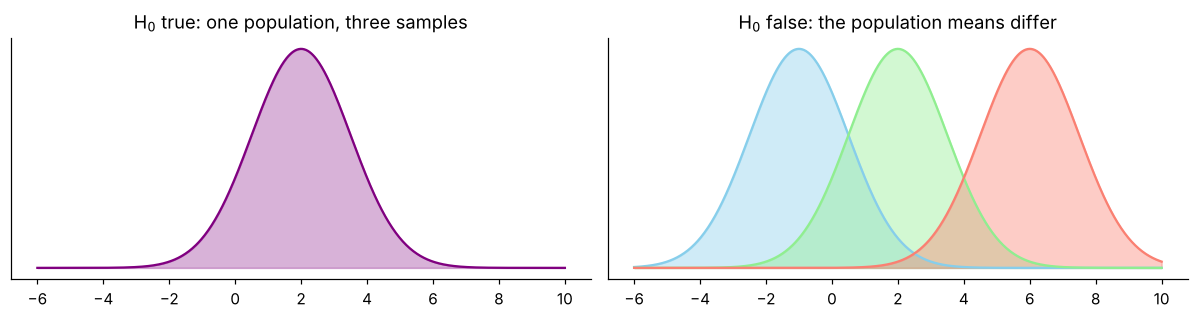

In [ ]:
x = np.linspace(-6, 10, 600)
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
axes[0].plot(x, stats.norm.pdf(x, 2, 1.5), color="purple"); axes[0].fill_between(x, stats.norm.pdf(x, 2, 1.5), color="purple", alpha=0.3)
axes[0].set_title("H$_0$ true: one population, three samples")
for mu, c in zip([-1, 2, 6], ["skyblue", "lightgreen", "salmon"]):
    axes[1].plot(x, stats.norm.pdf(x, mu, 1.5), color=c); axes[1].fill_between(x, stats.norm.pdf(x, mu, 1.5), color=c, alpha=0.4)
axes[1].set_title("H$_0$ false: the population means differ")
for ax in axes: ax.set_yticks([])
plt.tight_layout(); plt.show()

## 5. Between and within

- Variation **between** groups: how far the group means are from the overall mean.
- Variation **within** groups: how far individual scores are from their own group mean.

If all population means are equal, the between-group variation is only an echo of the within-group variation. The **F statistic** compares the two. F close to 1 is what we expect under H<sub>0</sub>; a large F is evidence against it.

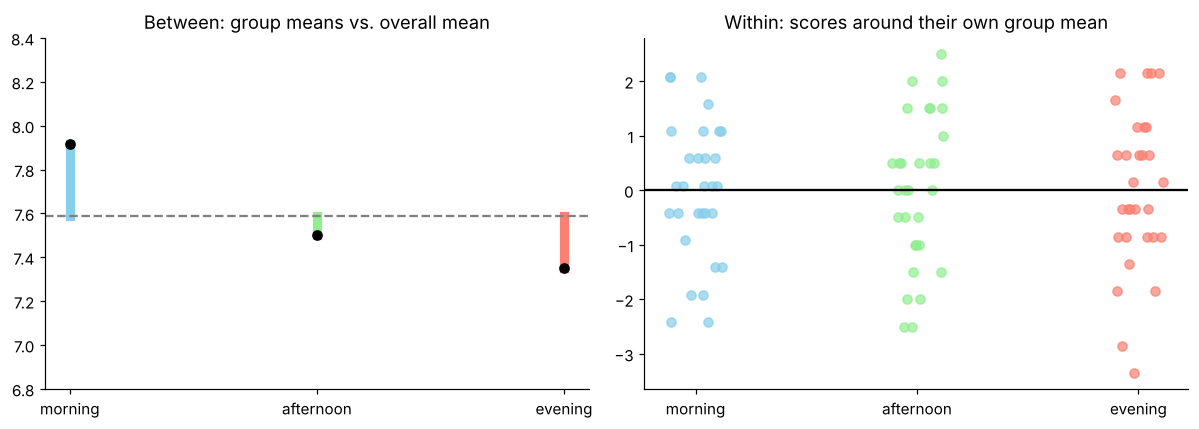

In [ ]:
grand = scores["score"].mean()
gm = scores.groupby("section")["score"].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for i, s in enumerate(order):
    axes[0].plot([i, i], [grand, gm[s]], color=palette[s], lw=6)
    axes[0].scatter(i, gm[s], color="black", zorder=3)
axes[0].axhline(grand, color="gray", ls="--"); axes[0].set_ylim(6.8, 8.4)
axes[0].set_xticks(range(3)); axes[0].set_xticklabels(order); axes[0].set_title("Between: group means vs. overall mean")
for i, s in enumerate(order):
    v = scores.loc[scores["section"] == s, "score"]
    axes[1].scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-0.12, 0.12, len(v)), v - v.mean(), color=palette[s], alpha=0.7)
axes[1].axhline(0, color="black"); axes[1].set_xticks(range(3)); axes[1].set_xticklabels(order)
axes[1].set_title("Within: scores around their own group mean")
plt.tight_layout(); plt.show()

In [ ]:
f_stat, p_value = stats.f_oneway(test_scores["morning"], test_scores["afternoon"], test_scores["evening"])
print(f"F = {f_stat:.3f}, p-value = {p_value:.3f}")

F = 1.401, p-value = 0.252


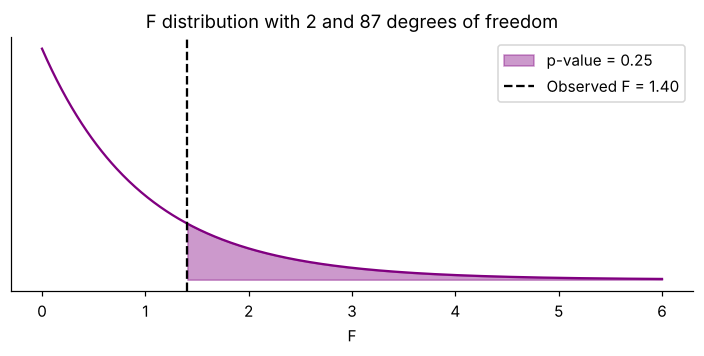

In [ ]:
x = np.linspace(0, 6, 500); y = stats.f.pdf(x, 2, 87)
plt.figure(figsize=(8, 3))
plt.plot(x, y, color="purple"); plt.fill_between(x, y, where=x >= f_stat, color="purple", alpha=0.4, label=f"p-value = {p_value:.2f}")
plt.axvline(f_stat, color="black", ls="--", label=f"Observed F = {f_stat:.2f}")
plt.title("F distribution with 2 and 87 degrees of freedom"); plt.xlabel("F"); plt.yticks([]); plt.legend(); plt.show()

## 6. A new idea: shuffling the labels

Where does the F distribution come from? Here is a way to see it without formulas. If the section does not matter, the labels "morning", "afternoon", "evening" are arbitrary: we could shuffle the scores among the sections and nothing important would change. So we shuffle the labels many times, compute F each time, and see how often a shuffled F is as large as the one we observed.

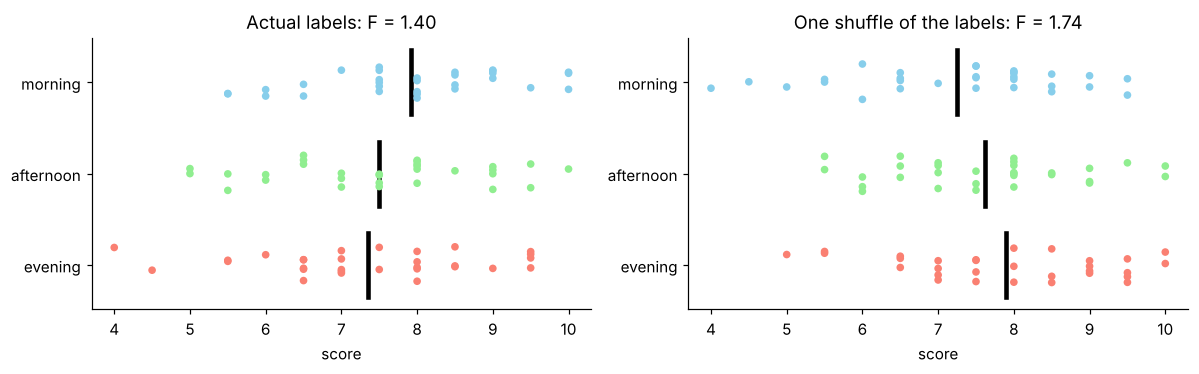

In [ ]:
rng = np.random.default_rng(3)
shuffled = scores.copy(); shuffled["section"] = rng.permutation(scores["section"].to_numpy())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True)
for ax, d, title in zip(axes, [scores, shuffled], ["Actual labels", "One shuffle of the labels"]):
    sns.stripplot(data=d, x="score", y="section", order=order, hue="section", palette=palette, legend=False, ax=ax, size=5, jitter=0.2)
    for i, s in enumerate(order):
        m = d.loc[d["section"] == s, "score"].mean(); ax.plot([m, m], [i - 0.35, i + 0.35], color="black", lw=3)
    ax.set_title(f"{title}: F = {stats.f_oneway(*[d.loc[d['section'] == s, 'score'] for s in order]).statistic:.2f}"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [ ]:
all_scores = scores["score"].to_numpy()
rng = np.random.default_rng(2)
shuffled_f = np.array([stats.f_oneway(*np.split(rng.permutation(all_scores), 3)).statistic for _ in range(10000)])
print(f"Share of shuffles with F at least as large as observed: {np.mean(shuffled_f >= f_stat):.3f}")
print(f"p-value from the F distribution (ANOVA):              {p_value:.3f}")

Share of shuffles with F at least as large as observed: 0.256
p-value from the F distribution (ANOVA):              0.252


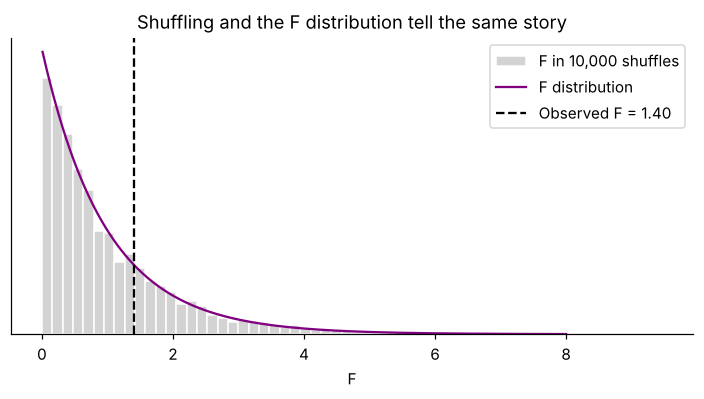

In [ ]:
plt.figure(figsize=(8, 3.5))
plt.hist(shuffled_f, bins=60, density=True, color="lightgray", edgecolor="white", label="F in 10,000 shuffles")
x = np.linspace(0.01, 8, 400); plt.plot(x, stats.f.pdf(x, 2, 87), color="purple", label="F distribution")
plt.axvline(f_stat, color="black", ls="--", label=f"Observed F = {f_stat:.2f}")
plt.xlabel("F"); plt.yticks([]); plt.legend(); plt.title("Shuffling and the F distribution tell the same story"); plt.show()

The shuffled values of F follow the F distribution, and the two p-values are nearly identical. The F distribution is a shortcut that tells us, without shuffling, how large F tends to be when all population means are equal.

**Question to you:** at α = 0.05, what do you conclude about the mean scores in the three sections? Does this mean that the three population means are equal?